# LAB 2 – Bài 4: Phân lớp chất lượng rượu vang đỏ – Red Wine Quality (Trang 26)
Thực hiện lại từ Câu 3 của phần *Yêu cầu lập trình*. Thuộc tính quyết định: `quality`. Cần file `winequality-red.csv`.


In [1]:
HO_TEN = "Lê Quốc Trung"
MSSV = "6451071082"


def in_ten():
    print(f"{HO_TEN} - {MSSV}")


in_ten()

Lê Quốc Trung - 6451071082


## Chuẩn bị: thư viện và hàm dùng chung

In [2]:
%matplotlib inline
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics


import urllib.request

# ID file trên Google Drive (lấy từ link chia sẻ .../file/d/<ID>/view)
FILE_IDS = {
    "adult.data.csv": "1BYKP73pyzphA5YHR1fVvn2A0kBpr09TB",
    "adult.test.csv": "1Vh7e1IBL0SRxjT3gU_v_rnIcAT18griD",
    "heart.csv": "10N9jGzMn-MagDWXORdP-qIpwC3omZJHb",
    "mushrooms.csv": "11OXFpnwUwK_Ka9BFmboMoT9RhTRe3CFW",
    "winequality-red.csv": "1rzLiUi64RLmMV8ApudCt6aJyv_OkhADH",
}


def tai_tu_drive(file_id, ten_luu):
    """Tải file công khai từ Google Drive theo ID và lưu thành ten_luu."""
    url = f"https://drive.google.com/uc?export=download&id={file_id}"
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=120) as r:
        noi_dung = r.read()
    if noi_dung.lstrip()[:15].lower().startswith((b"<!doctype html", b"<html")):
        raise RuntimeError("Drive trả về trang web thay vì file: kiểm tra file đã chia sẻ 'Bất kỳ ai có đường liên kết' chưa.")
    with open(ten_luu, "wb") as f:
        f.write(noi_dung)


def tim_file(ten_file):
    """Trả về đường dẫn file dữ liệu: dùng bản có sẵn trong máy, nếu chưa có thì tải từ Drive theo FILE_IDS."""
    for thu_muc in [".", "data", "/content"]:
        p = os.path.join(thu_muc, ten_file)
        if os.path.isfile(p):
            print("Đã tìm thấy:", p)
            return p
    if ten_file not in FILE_IDS:
        raise FileNotFoundError(f"Không có file '{ten_file}' và cũng không có ID Drive tương ứng.")
    print(f"Đang tải '{ten_file}' từ Google Drive...")
    tai_tu_drive(FILE_IDS[ten_file], ten_file)
    print("Đã tải xong:", ten_file)
    return ten_file


ket_qua = {}   # lưu chỉ số của từng mô hình để so sánh ở Câu 10


def tinh_chi_so(y_true, y_pred, pos_label=None):
    d = {"Accuracy": metrics.accuracy_score(y_true, y_pred)}
    for avg in ("macro", "weighted"):
        p, r, f, _ = metrics.precision_recall_fscore_support(y_true, y_pred, average=avg, zero_division=0)
        d[f"Precision ({avg})"], d[f"Recall ({avg})"], d[f"F1 ({avg})"] = p, r, f
    if pos_label is not None:
        p, r, f, _ = metrics.precision_recall_fscore_support(
            y_true, y_pred, labels=[pos_label], average=None, zero_division=0)
        d[f"Precision [{pos_label}]"], d[f"Recall [{pos_label}]"], d[f"F1 [{pos_label}]"] = p[0], r[0], f[0]
    return d


def danh_gia_mo_hinh(ten, y_test, y_pred, labels, pos_label=None, cmap="Blues"):
    """In accuracy + classification report, vẽ heatmap ma trận nhầm lẫn, lưu chỉ số để so sánh."""
    score = metrics.accuracy_score(y_test, y_pred)
    print("Accuracy:", score)
    print("Report:\n", metrics.classification_report(y_test, y_pred, labels=labels, zero_division=0))
    cm = metrics.confusion_matrix(y_test, y_pred, labels=labels)
    plt.figure(figsize=(8, 8))
    sns.heatmap(cm, annot=True, fmt="d", linewidths=.5, square=True, cmap=cmap,
                xticklabels=labels, yticklabels=labels)
    plt.ylabel("Actual label")
    plt.xlabel("Predicted label")
    plt.title(f"{ten} Accuracy Score: {score:.4f}", size=15)
    plt.show()
    ket_qua[ten] = tinh_chi_so(y_test, y_pred, pos_label)
    return cm


def ve_cay(clf, feature_names, ten_file, max_depth=None, figsize=(50, 24), fontsize=10):
    """Vẽ cây quyết định và lưu thành file PNG (dpi=100)."""
    fig, ax = plt.subplots(figsize=figsize)
    tree.plot_tree(clf, max_depth=max_depth, feature_names=list(feature_names),
                   class_names=[str(c) for c in clf.classes_], filled=True, fontsize=fontsize, ax=ax)
    plt.savefig(ten_file, dpi=100)
    plt.show()
    print("Đã lưu cây vào file:", ten_file)

## Chuẩn bị: nhập dữ liệu


In [3]:
in_ten()
data = pd.read_csv(tim_file("winequality-red.csv"), sep=None, engine="python")   # tự nhận dấu phân cách , hoặc ;
print("Kích thước:", data.shape)
print("Số ô trống:", int(data.isna().sum().sum()))
data = data.dropna().reset_index(drop=True)
data.info()
display(data.head())

Lê Quốc Trung - 6451071082
Đang tải 'winequality-red.csv' từ Google Drive...
Đã tải xong: winequality-red.csv
Kích thước: (1599, 12)
Số ô trống: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
me

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson
Vẽ heatmap (màu càng đậm → mức độ tương đồng càng thấp). Sau đó tự động tìm các cặp cột **feature** có |r| vượt ngưỡng và loại bỏ.

Lê Quốc Trung - 6451071082


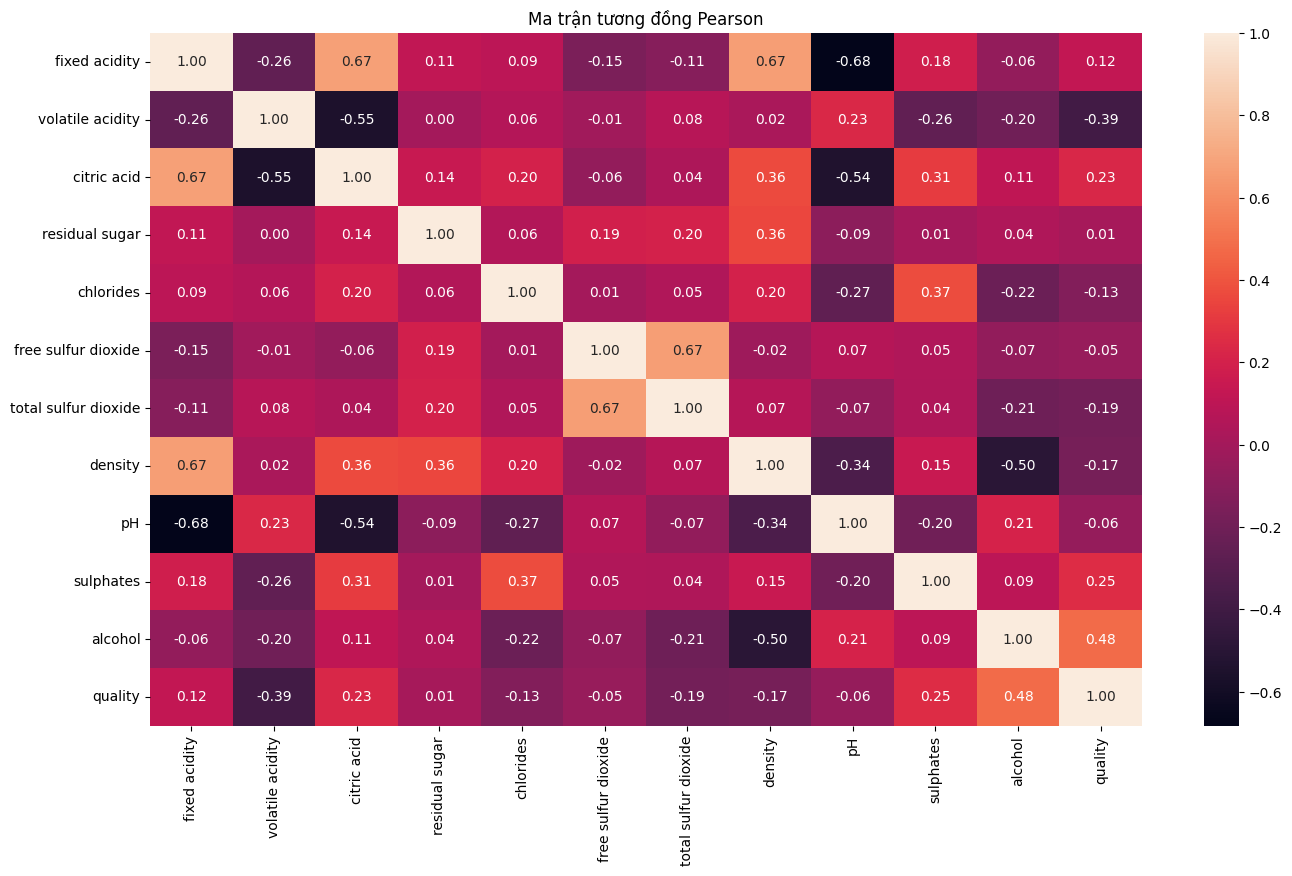

In [4]:
in_ten()
NHAN = "quality"   # thuộc tính quyết định

plt.figure(figsize=(16, 9))
sns.heatmap(data.corr(method="pearson", numeric_only=True), annot=True, fmt=".2f")
plt.title("Ma trận tương đồng Pearson")
plt.show()

In [5]:
in_ten()
NGUONG_PEARSON = 0.8   # |r| > ngưỡng này được xem là tương đồng cao

corr = data.drop(columns=[NHAN]).corr(method="pearson", numeric_only=True).abs()
tam_giac_tren = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
cap_cao = [(a, b, round(float(tam_giac_tren.loc[a, b]), 3))
           for a in tam_giac_tren.index for b in tam_giac_tren.columns
           if pd.notna(tam_giac_tren.loc[a, b]) and tam_giac_tren.loc[a, b] > NGUONG_PEARSON]
cot_loai = sorted({b for _, b, _ in cap_cao})

if cap_cao:
    print("Các cặp cột tương đồng cao:", cap_cao)
    print("Loại bỏ các cột:", cot_loai)
else:
    print(f"Không có cặp cột nào có |r| > {NGUONG_PEARSON} => không cần loại bỏ cột nào.")

data = data.drop(columns=cot_loai)
print("Các cột còn lại:", list(data.columns))

Lê Quốc Trung - 6451071082
Không có cặp cột nào có |r| > 0.8 => không cần loại bỏ cột nào.
Các cột còn lại: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


## Câu 4: Tách các cột thành hai phần
`features` chứa các thuộc tính bình thường, `labels` chứa riêng thuộc tính quyết định.

In [6]:
in_ten()
features = data.drop(NHAN, axis=1)
labels = data[NHAN]
print("features:", features.shape, "| labels:", labels.shape)
print(labels.value_counts())

Lê Quốc Trung - 6451071082
features: (1599, 11) | labels: (1599,)
quality
5    681
6    638
7    199
4     53
8     18
3     10
Name: count, dtype: int64


## Câu 5: Chuyển các cột không phải dạng số về one-hot vector
Xác định các cột không phải dạng số rồi dùng `pd.get_dummies`.

In [7]:
in_ten()
cot_chu = features.select_dtypes(exclude="number").columns
print("Các cột không phải dạng số:", list(cot_chu))

if len(cot_chu) > 0:
    features_onehot = pd.get_dummies(features, columns=cot_chu, dtype=int)
else:
    features_onehot = features.copy()
    print("=> Tất cả các cột đều là dạng số, không cần chuyển one-hot.")

print("Kích thước sau khi xử lý:", features_onehot.shape)
display(features_onehot.head())

Lê Quốc Trung - 6451071082
Các cột không phải dạng số: []
=> Tất cả các cột đều là dạng số, không cần chuyển one-hot.
Kích thước sau khi xử lý: (1599, 11)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4


## Câu 6: Chia dữ liệu thành hai phần huấn luyện (70%) và kiểm thử (30%)
Theo đề: `train_test_split(X, y, test_size=0.3, random_state=42)`.

In [8]:
in_ten()
X_train, X_test, y_train, y_test = train_test_split(features_onehot, labels, test_size=0.3, random_state=42)

LOP = sorted(labels.unique())
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Các lớp:", LOP)

Lê Quốc Trung - 6451071082
X_train: (1119, 11) | X_test: (480, 11)
Các lớp: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


## Câu 7: Xây dựng cây ID3 (`criterion="entropy"` – phân nhánh theo information gain)
Gồm 3 phần: huấn luyện + dự đoán → kiểm thử bằng ma trận nhầm lẫn → biểu diễn cây.

In [9]:
in_ten()
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf_id3.fit(X_train, y_train)          # huấn luyện
id3_pred = clf_id3.predict(X_test)     # dự đoán trên dữ liệu kiểm thử
print("Số nút:", clf_id3.tree_.node_count, "| số lá:", clf_id3.get_n_leaves(), "| độ sâu:", clf_id3.get_depth())

Lê Quốc Trung - 6451071082
Số nút: 545 | số lá: 273 | độ sâu: 18


Lê Quốc Trung - 6451071082
Accuracy: 0.5833333333333334
Report:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.08      0.12      0.10        17
           5       0.70      0.66      0.68       195
           6       0.60      0.60      0.60       200
           7       0.43      0.46      0.44        61
           8       0.25      0.17      0.20         6

    accuracy                           0.58       480
   macro avg       0.34      0.33      0.34       480
weighted avg       0.59      0.58      0.59       480



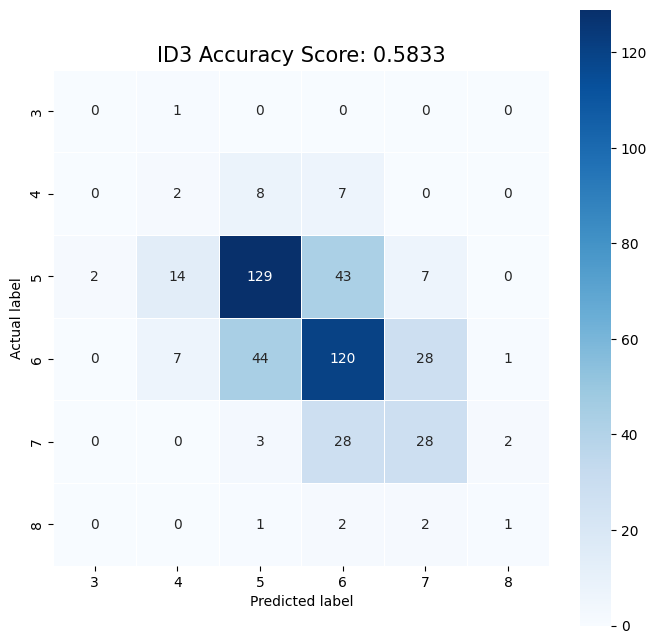

Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):
[[  0   1   0   0   0   0]
 [  0   2   8   7   0   0]
 [  2  14 129  43   7   0]
 [  0   7  44 120  28   1]
 [  0   0   3  28  28   2]
 [  0   0   1   2   2   1]]


In [10]:
in_ten()
id3_cm = danh_gia_mo_hinh("ID3", y_test, id3_pred, LOP, pos_label=None, cmap="Blues")
print("Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):")
print(id3_cm)

Lê Quốc Trung - 6451071082


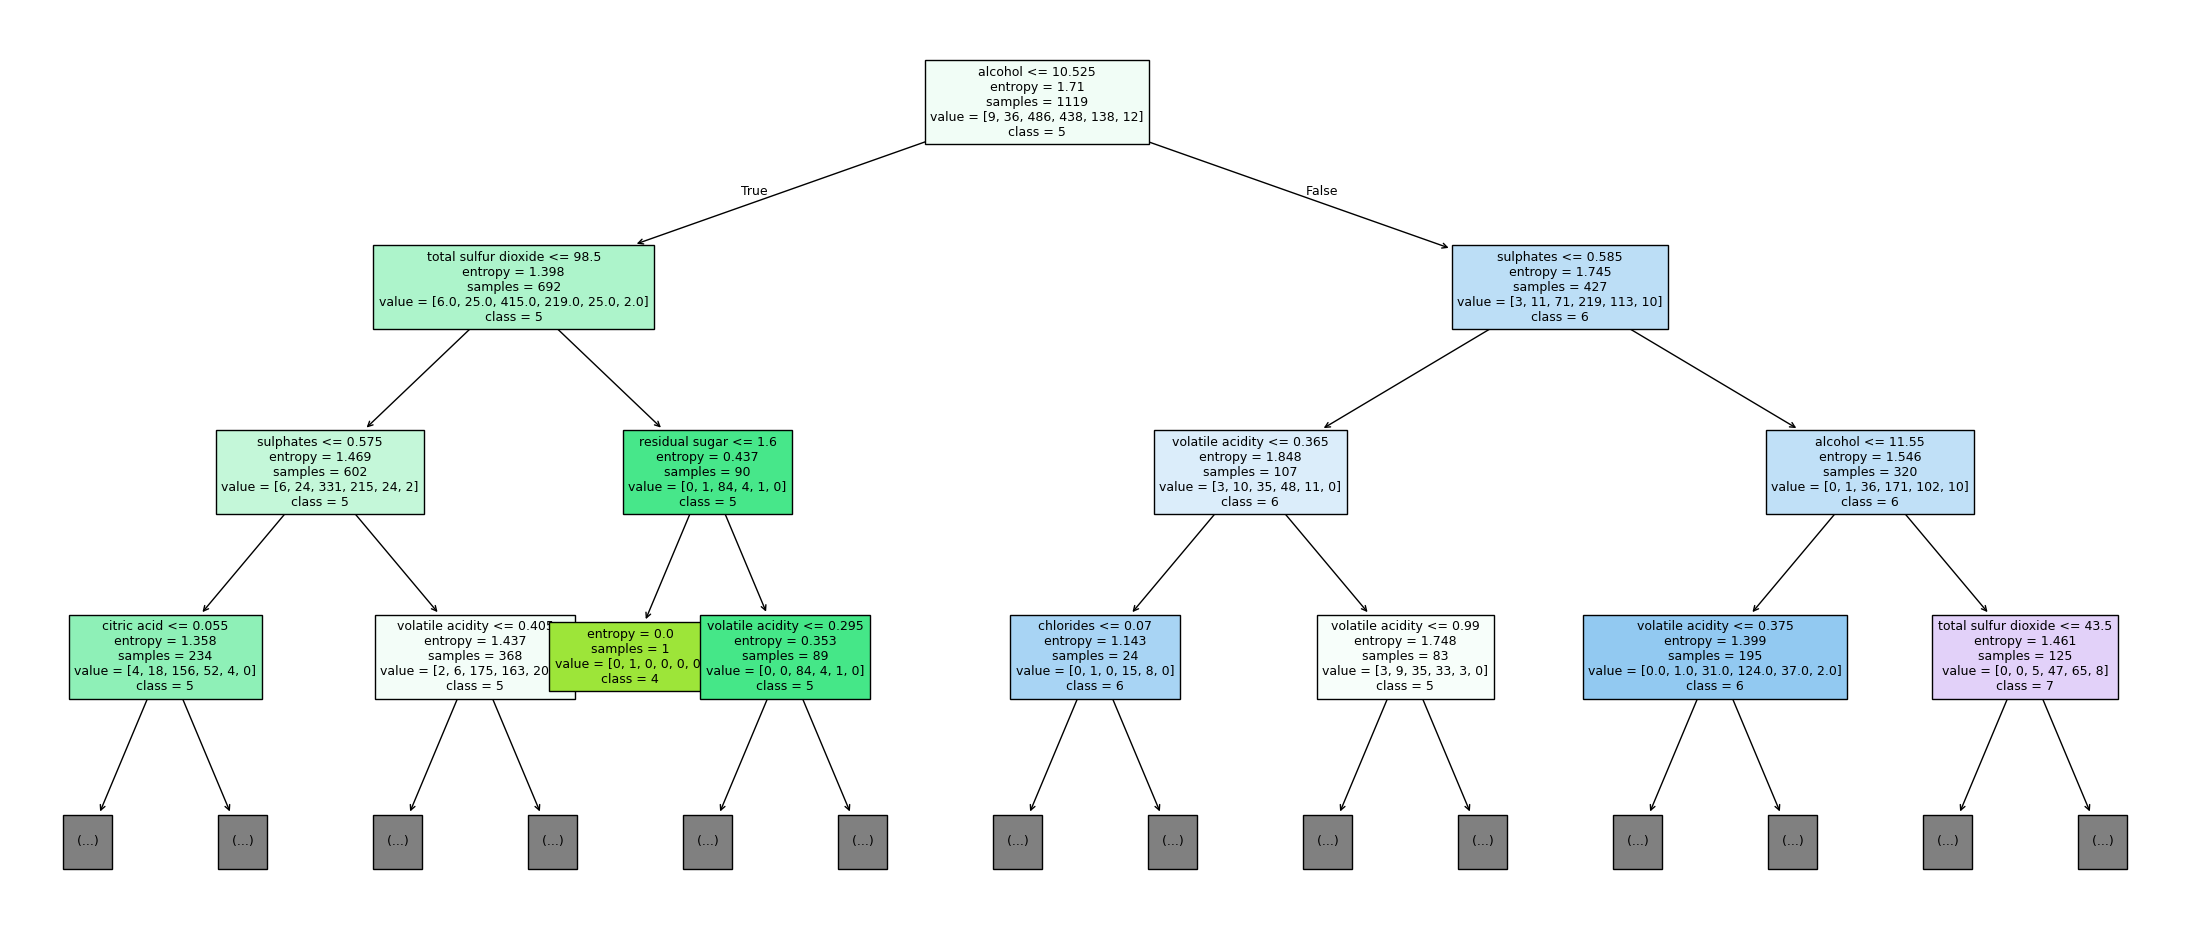

Đã lưu cây vào file: cay_ID3_rut_gon.png


In [11]:
in_ten()
# Cây rút gọn (3 mức trên cùng) để đọc được trên màn hình
ve_cay(clf_id3, X_train.columns, "cay_ID3_rut_gon.png", max_depth=3, figsize=(28, 12), fontsize=9)

Lê Quốc Trung - 6451071082


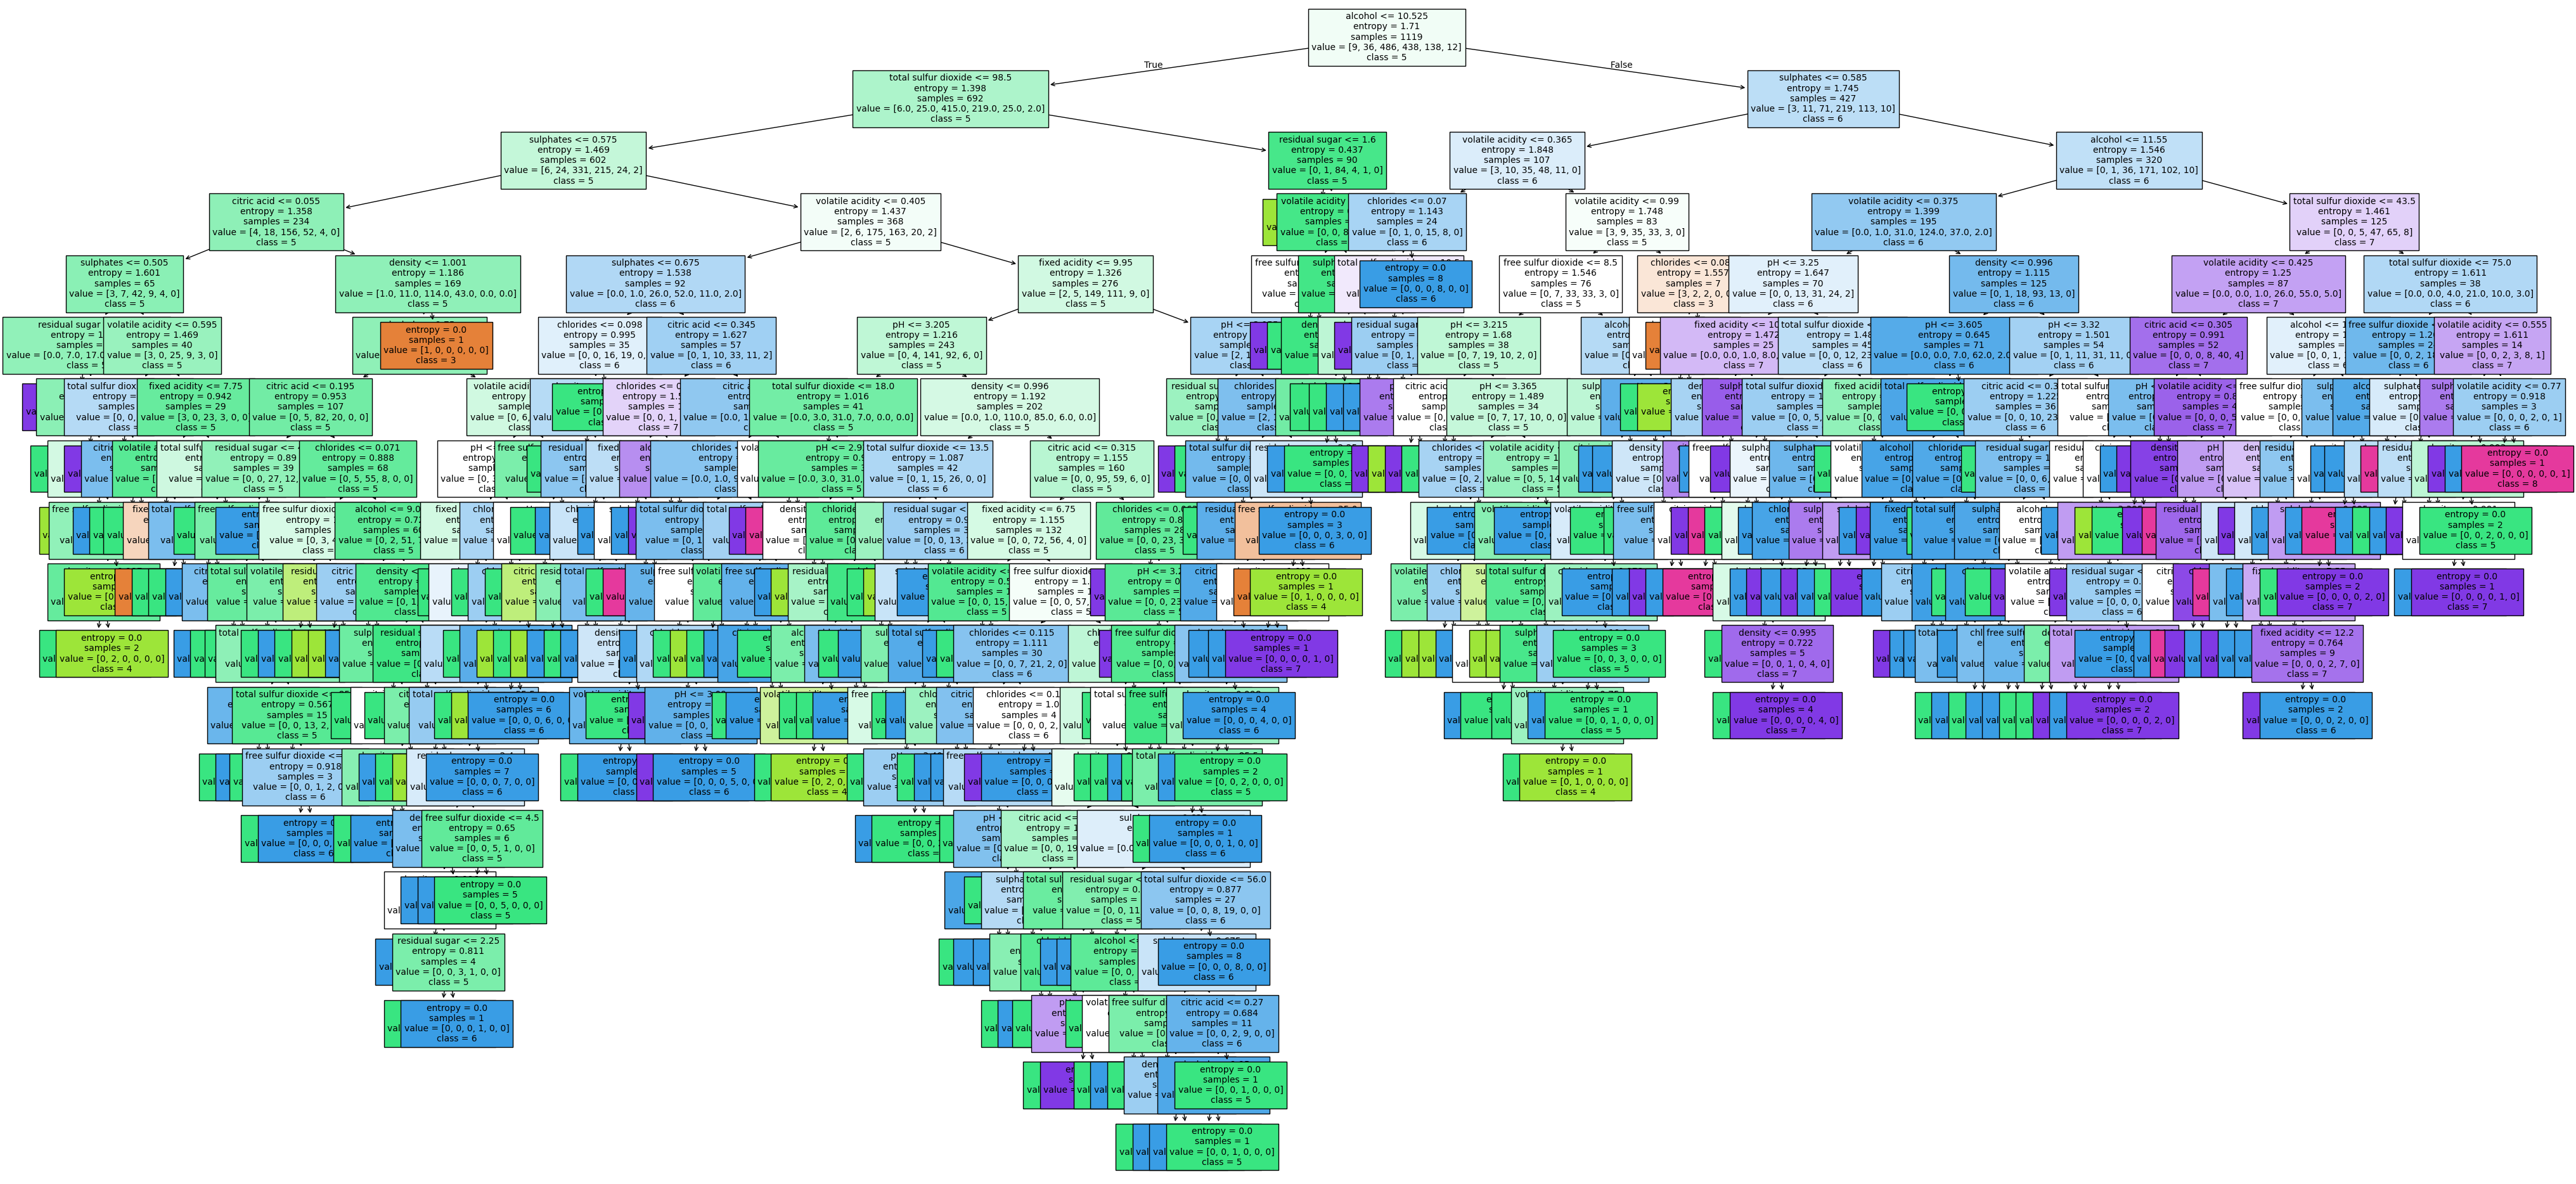

Đã lưu cây vào file: cay_ID3.png


In [12]:
in_ten()
# Cây đầy đủ (ảnh rất lớn; đặt False nếu máy chậm/thiếu RAM)
VE_CAY_DAY_DU = True
if VE_CAY_DAY_DU:
    ve_cay(clf_id3, X_train.columns, "cay_ID3.png", figsize=(50, 24), fontsize=10)

## Câu 8: Xây dựng cây CART (`criterion="gini"`)
Thực hiện tương tự Câu 7, thay `criterion="gini"`.

In [13]:
in_ten()
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)
cart_pred = clf_cart.predict(X_test)
print("Số nút:", clf_cart.tree_.node_count, "| số lá:", clf_cart.get_n_leaves(), "| độ sâu:", clf_cart.get_depth())

Lê Quốc Trung - 6451071082
Số nút: 573 | số lá: 287 | độ sâu: 19


Lê Quốc Trung - 6451071082
Accuracy: 0.5625
Report:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.07      0.06      0.06        17
           5       0.64      0.62      0.63       195
           6       0.57      0.58      0.57       200
           7       0.45      0.49      0.47        61
           8       0.33      0.33      0.33         6

    accuracy                           0.56       480
   macro avg       0.34      0.35      0.35       480
weighted avg       0.56      0.56      0.56       480



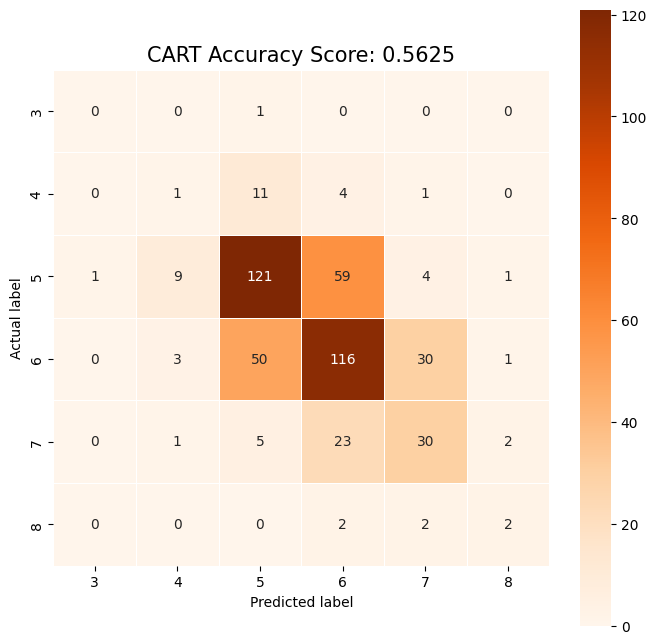

Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):
[[  0   0   1   0   0   0]
 [  0   1  11   4   1   0]
 [  1   9 121  59   4   1]
 [  0   3  50 116  30   1]
 [  0   1   5  23  30   2]
 [  0   0   0   2   2   2]]


In [14]:
in_ten()
cart_cm = danh_gia_mo_hinh("CART", y_test, cart_pred, LOP, pos_label=None, cmap="Oranges")
print("Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):")
print(cart_cm)

Lê Quốc Trung - 6451071082


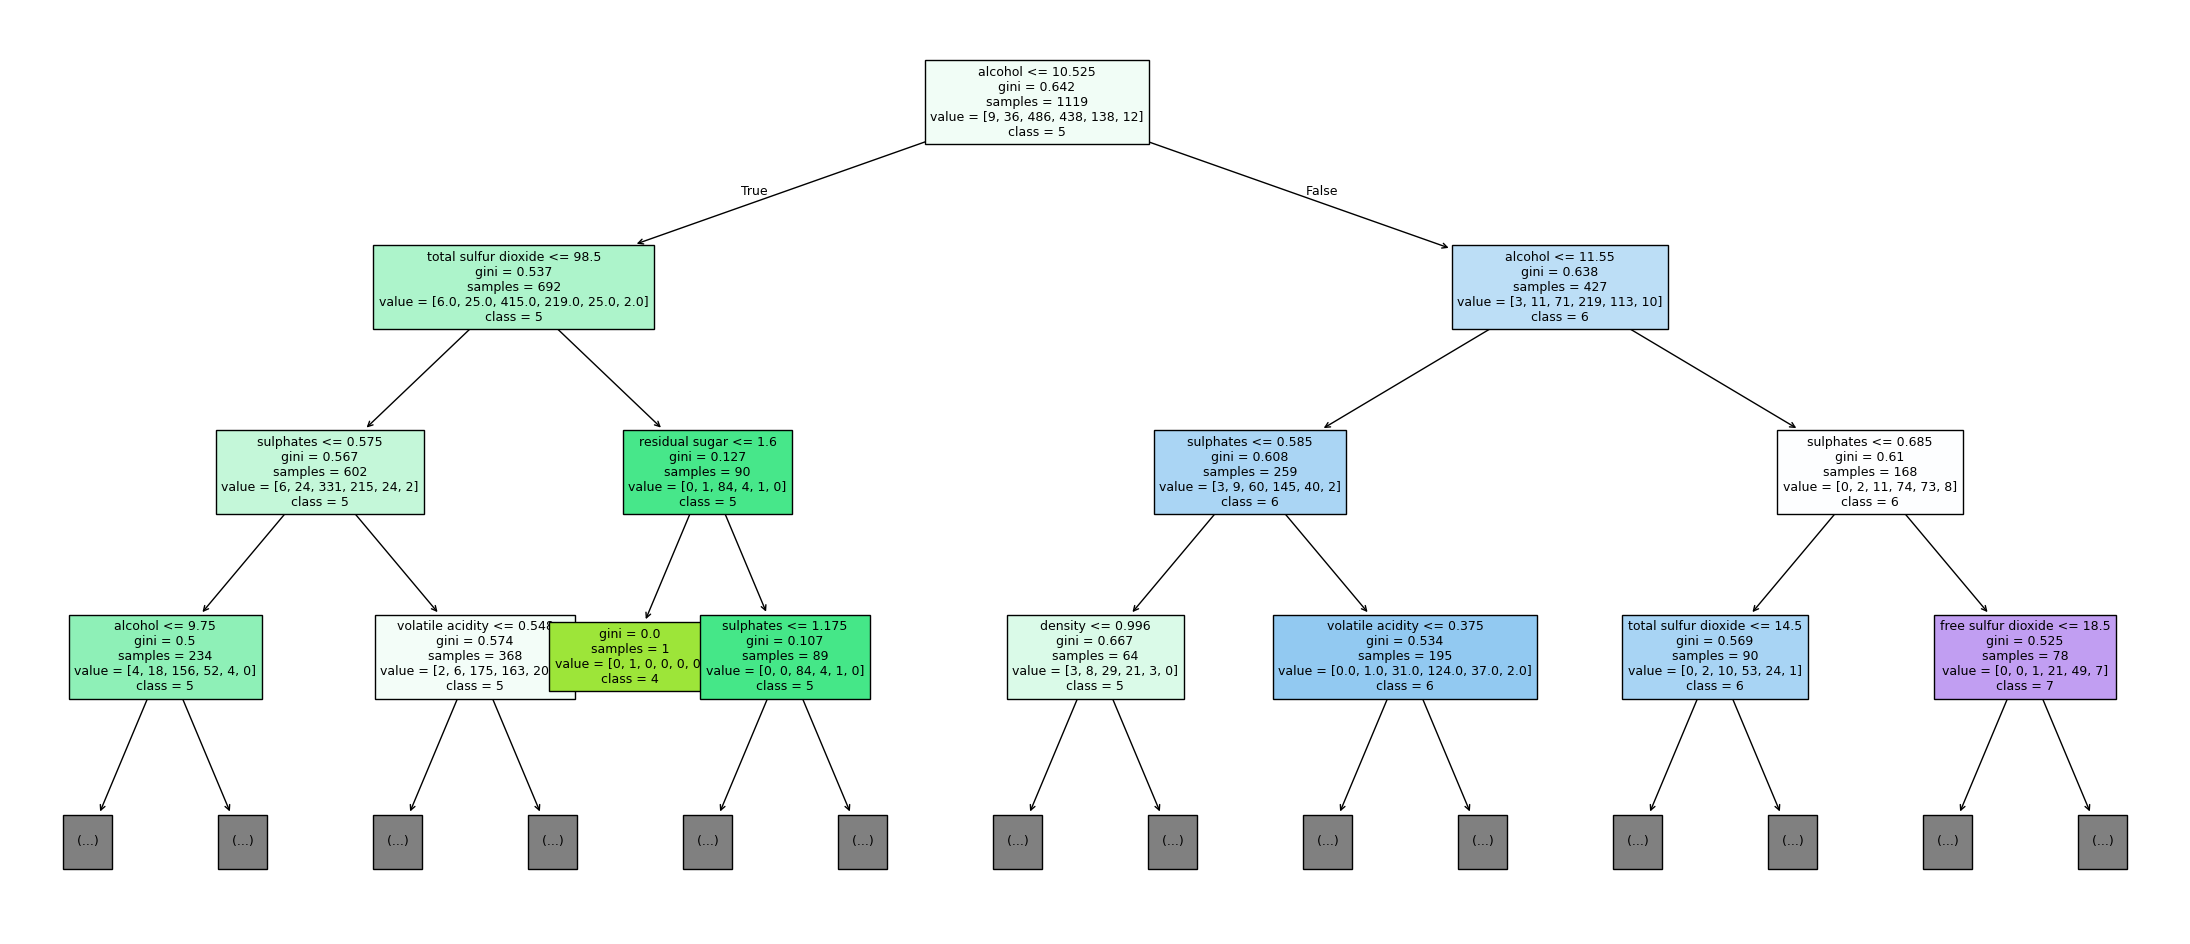

Đã lưu cây vào file: cay_CART_rut_gon.png


In [15]:
in_ten()
ve_cay(clf_cart, X_train.columns, "cay_CART_rut_gon.png", max_depth=3, figsize=(28, 12), fontsize=9)

Lê Quốc Trung - 6451071082


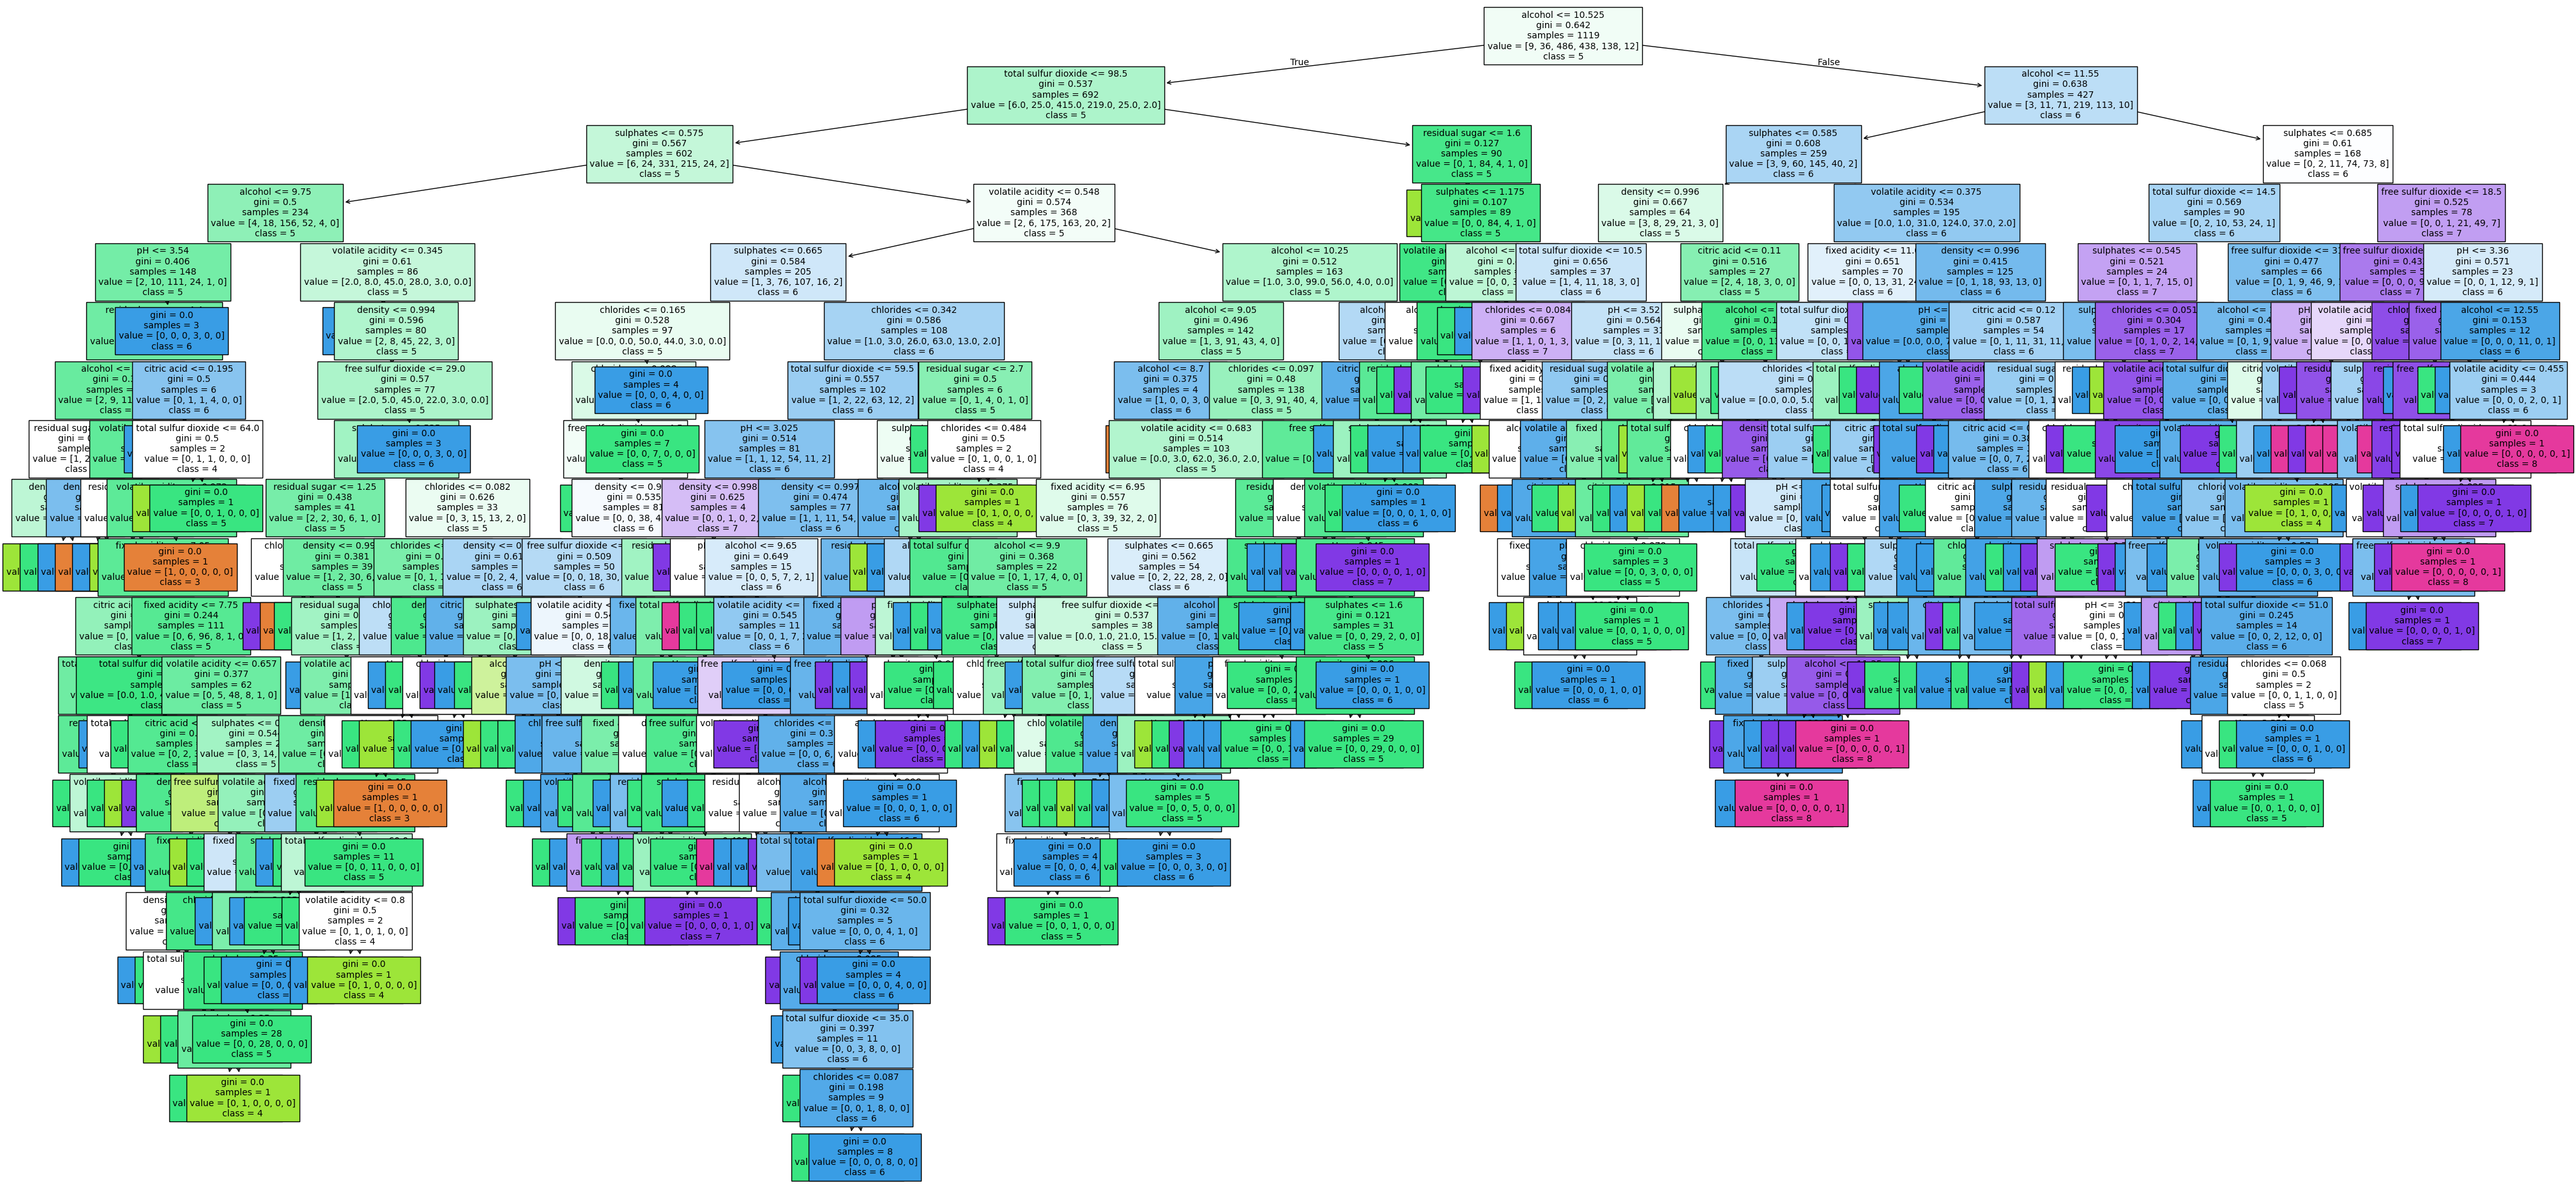

Đã lưu cây vào file: cay_CART.png


In [16]:
in_ten()
VE_CAY_DAY_DU = True
if VE_CAY_DAY_DU:
    ve_cay(clf_cart, X_train.columns, "cay_CART.png", figsize=(50, 24), fontsize=10)

## Câu 9: Xây dựng mô hình phân lớp Naïve Bayes (`GaussianNB`)

In [17]:
in_ten()
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

Lê Quốc Trung - 6451071082


Lê Quốc Trung - 6451071082
Accuracy: 0.5416666666666666
Report:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.12      0.12      0.12        17
           5       0.68      0.62      0.65       195
           6       0.52      0.54      0.53       200
           7       0.40      0.49      0.44        61
           8       0.00      0.00      0.00         6

    accuracy                           0.54       480
   macro avg       0.29      0.29      0.29       480
weighted avg       0.55      0.54      0.54       480



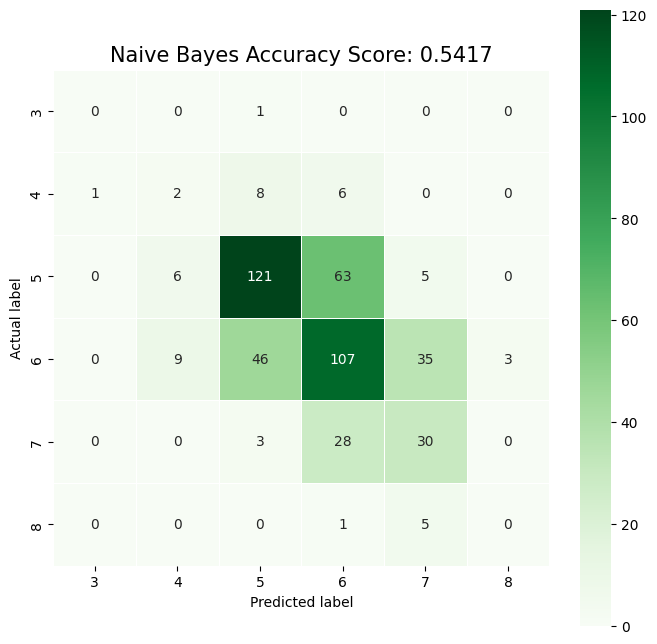

Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):
[[  0   0   1   0   0   0]
 [  1   2   8   6   0   0]
 [  0   6 121  63   5   0]
 [  0   9  46 107  35   3]
 [  0   0   3  28  30   0]
 [  0   0   0   1   5   0]]


In [18]:
in_ten()
bayes_cm = danh_gia_mo_hinh("Naive Bayes", y_test, bayes_pred, LOP, pos_label=None, cmap="Greens")
print("Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán):")
print(bayes_cm)

## Câu 10: So sánh kết quả của các mô hình

Lê Quốc Trung - 6451071082


,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted)
ID3,0.5833,0.3436,0.3341,0.3368,0.5941,0.5833,0.5883
CART,0.5625,0.3441,0.3474,0.3455,0.5620,0.5625,0.5620
Naive Bayes,0.5417,0.2859,0.2942,0.2890,0.5471,0.5417,0.5433


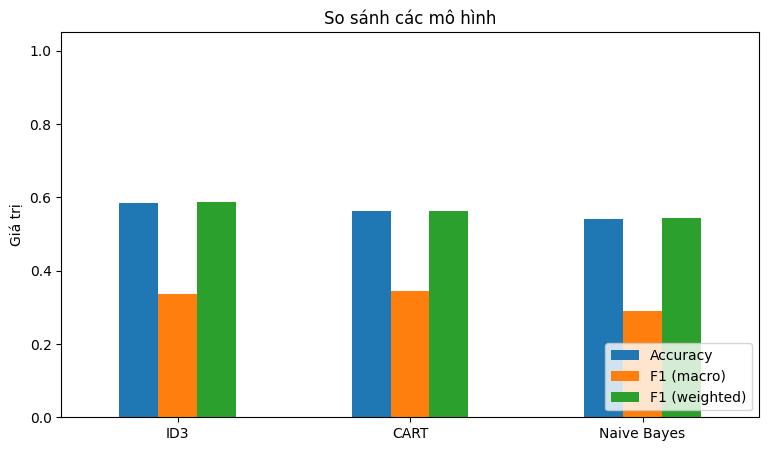

Mô hình có Accuracy cao nhất  : ID3 (0.5833)
Mô hình có F1 (macro) cao nhất: CART (0.3455)


In [19]:
in_ten()
bang_ss = pd.DataFrame(ket_qua).T.round(4)
display(bang_ss)

bang_ss[["Accuracy", "F1 (macro)", "F1 (weighted)"]].plot(kind="bar", figsize=(9, 5), rot=0)
plt.title("So sánh các mô hình")
plt.ylabel("Giá trị")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.show()

print("Mô hình có Accuracy cao nhất  :", bang_ss["Accuracy"].idxmax(), f"({bang_ss['Accuracy'].max():.4f})")
print("Mô hình có F1 (macro) cao nhất:", bang_ss["F1 (macro)"].idxmax(), f"({bang_ss['F1 (macro)'].max():.4f})")

### Nhận xét (đối chiếu với bảng số liệu ở trên rồi chỉnh lại cho khớp kết quả chạy thực tế)
- Đây là bài toán **nhiều lớp** (điểm 3–8) và **mất cân bằng nặng** (đa số rượu điểm 5, 6; các điểm 3, 4, 8 rất ít) nên Accuracy chỉ ở mức trung bình, và các chỉ số *macro* thấp hơn *weighted* rõ rệt.
- Hai cây (ID3, CART) thường cho kết quả gần nhau; cây phát triển hết độ sâu dễ overfit.
- `GaussianNB` giả định các chỉ số hóa lý độc lập, nhưng thực tế nhiều cột tương quan (vd. `fixed acidity` – `density` – `pH`) nên kết quả thường thấp hơn cây.
- Các lớp quá ít mẫu không được dự đoán đúng → precision/recall của các lớp này bằng 0 (xem `classification_report`).